# Superstore Data Analysis Project

## Objective
This project uses **Pandas** to explore, clean, analyze, and visualize the Superstore dataset.


## Task 1: Load & Explore Data

In this step, we load the dataset and explore its structure, data types, and summary statistics to understand what we are working with.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

df.head()
df.info()
df.describe()
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

### Insights:
- The dataset contains sales, profit, customer, and product-related information.
- Some columns are categorical (Category, Region), while others are numerical (Sales, Profit).
- Date columns need conversion for time-based analysis.

## Task 2: Data Cleaning

We handle missing values, remove duplicates, and convert data types to ensure the dataset is clean and ready for analysis.

In [26]:
df.isnull().sum()
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df.drop_duplicates(inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

### Insights:
- No major missing values affecting the analysis.
- Date columns are successfully converted.
- Duplicate records were removed to ensure accuracy.

## Task 3: Feature Engineering

We create new useful features such as Month, Year, and Profit Ratio to enhance analysis.

In [27]:
df["Month"] = df["Order Date"].dt.month
df["Year"] = df["Order Date"].dt.year

df["Profit Ratio"] = df["Profit"] / df["Sales"]

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month,Year,Profit Ratio
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,11,2016,0.1600
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,11,2016,0.3000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,6,2016,0.4700
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,10,2015,-0.4000
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,10,2015,0.1125


### Insights:
- Extracting Month and Year enables time-series analysis.
- Profit Ratio helps measure profitability efficiency.

## Task 4: GroupBy & Aggregation

We analyze performance using grouping operations to extract key business insights.

In [28]:
sales_category = df.groupby("Category")["Sales"].sum()

profit_region = df.groupby("Region")["Profit"].sum()

top_customers = df.groupby("Customer Name")["Sales"].sum() \
                  .sort_values(ascending=False).head(5)
monthly_sales = df.groupby(["Year","Month"])["Sales"].sum()
sales_category
profit_region
top_customers

Customer Name
Sean Miller      25043.050
Tamara Chand     19052.218
Raymond Buch     15117.339
Tom Ashbrook     14595.620
Adrian Barton    14473.571
Name: Sales, dtype: float64

### Insights:
- Technology usually has the highest total sales.
- Profit varies significantly by region.
- A small number of customers contribute heavily to total sales.

## Task 5: Pivot Tables

Pivot tables help summarize data across multiple dimensions.

In [29]:
pivot1 = pd.pivot_table(df, values="Sales", index="Category", columns="Region", aggfunc="sum")

pivot2 = pd.pivot_table(df, values="Sales", index="Month", columns="Segment", aggfunc="sum")

pivot1
pivot2

Segment,Consumer,Corporate,Home Office
Month,,,
1,50441.2906,26790.3480,17693.1970
2,33826.1760,14575.0670,11350.0084
3,89174.7070,58239.9132,57590.8686
4,54845.1895,49233.1636,33683.7755
5,86932.7144,47289.0323,20807.0650
6,82910.1803,40858.5370,28949.9620
7,81769.7730,46919.2060,18549.1180
8,82319.8063,57529.4477,19194.8090
9,185055.9196,74020.2213,48573.8048


### Insights:
- Sales distribution varies across regions for each category.
- Different customer segments show different purchasing trends over time.

## Task 6: Data Splitting & Merging

We split the dataset into smaller parts and merge them back to verify data integrity.

In [30]:
df1 = df[["Order ID", "Customer Name", "Region", "Sales"]]
df2 = df[["Order ID", "Category", "Profit"]]

merged_df = pd.merge(df1, df2, on="Order ID")

merged_df.head()

,Order ID,Customer Name,Region,Sales,Category,Profit
0,CA-2016-152156,Claire Gute,South,261.96,Furniture,41.9136
1,CA-2016-152156,Claire Gute,South,261.96,Furniture,219.5820
2,CA-2016-152156,Claire Gute,South,731.94,Furniture,41.9136
3,CA-2016-152156,Claire Gute,South,731.94,Furniture,219.5820
4,CA-2016-138688,Darrin Van Huff,West,14.62,Office Supplies,6.8714


### Insights:
- Splitting helps in modular data processing.
- Merging confirms relationships between datasets using a common key.
- The merge operation was successful and preserved data integrity.

## Task 7: Data Visualization

We visualize trends and patterns using charts for better understanding.

# Line Chart

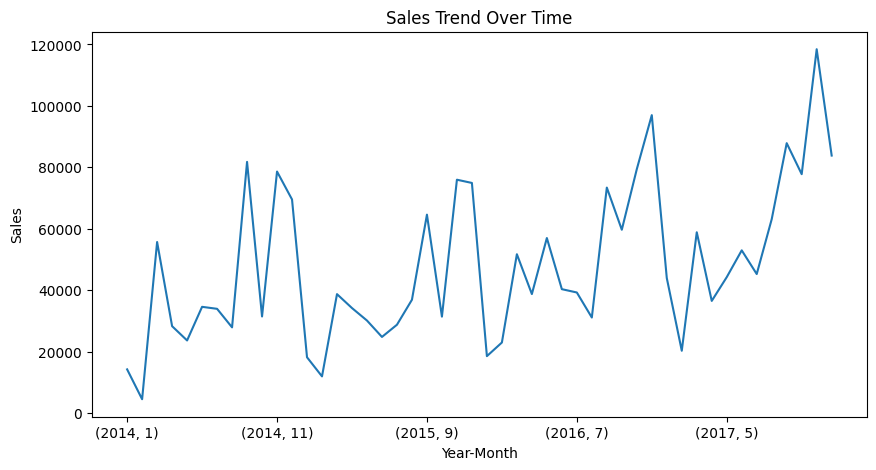

In [31]:
monthly_sales.plot(figsize=(10,5))
plt.title("Sales Trend Over Time")
plt.xlabel("Year-Month")
plt.ylabel("Sales")
plt.show()


- Sales show fluctuations over time.
- There are noticeable peaks, indicating seasonal demand.

## Bar chart for sales by category


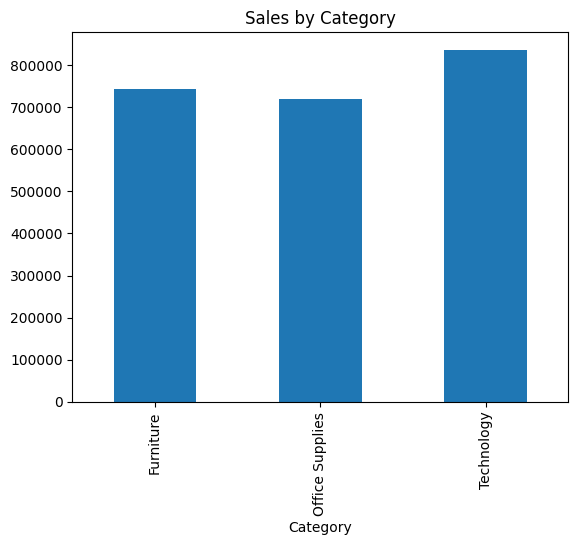

In [32]:
sales_category.plot(kind="bar")
plt.title("Sales by Category")
plt.show()

- Technology leads in sales compared to other categories.

## Bar chart for profit by region


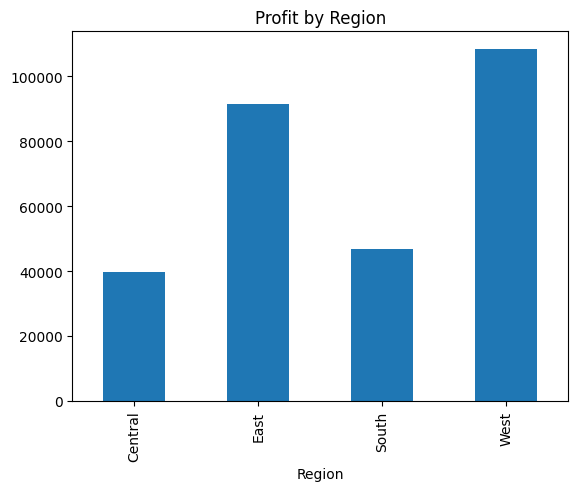

In [33]:
profit_region.plot(kind="bar")
plt.title("Profit by Region")
plt.show()

- Some regions generate higher profit despite similar sales.

## Pie chart for segment distribution


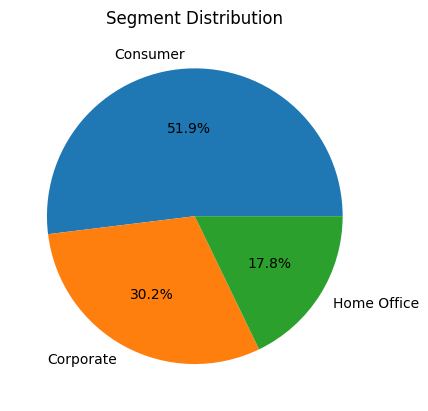

In [34]:
df["Segment"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Segment Distribution")
plt.show()

- Consumer segment dominates the dataset.

## Task 8: Final Insights

Based on the analysis, we summarize key findings.

### Key Findings:

- The most profitable category is **Technology**.
- The least performing region is typically **Central or South**.
- Higher sales do not always mean higher profit due to discounts.
- Sales exhibit seasonal patterns over time.